# Animals-10: exploratory data analysis and data visualization
**Group L01 - Team 14**  

EDA notebook for the [Animals-10 dataset](https://www.kaggle.com/datasets/alessiocorrado99/animals10)
(~26k images, 10 classes, Italian folder names translated to English).


The train / val / test split shown here is a stratified 70 / 15 / 15 split with seed 42.

| file | content |
|---|---|
| `eda_01_class_counts` | images per class, imbalance |
| `eda_02_split_distribution` | class share in train / val / test (stratification check) |
| `eda_03_sample_grid` | random examples of every class |
| `eda_04_image_sizes` | width x height, aspect ratio, resolution per class |
| `eda_05_file_size` | file size per class + format / colour-mode table |
| `eda_06_resize_effect` | what a 224x224 squash resize does to extreme aspect ratios |
| `eda_07_mean_images` | the mean image of every class |
| `eda_08_hue_by_class` | hue distribution per class |
| `eda_09_image_quality` | brightness, contrast, colourfulness, sharpness per class |
| `eda_10_rgb_histogram` | pixel-intensity histograms + dataset mean / std vs ImageNet |
| `eda_11_duplicates_*` | exact / near duplicates, across splits and across classes (leakage, label noise) |
| `eda_12_outliers` | smallest, most elongated, darkest, blurriest, grayscale images |
| `eda_13_tsne` | t-SNE of raw pixels and of HSV colour histograms |

# 0. Setup

In [ ]:
import os, sys, io, json, math, glob, hashlib, subprocess, warnings, pickle, time
from collections import Counter
from multiprocessing import Pool

IN_COLAB, SMOKE = "google.colab" in sys.modules, False

def pip_install(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)


for _mod, _pkg in (("kagglehub", "kagglehub"), ("cv2", "opencv-python-headless"), ("sklearn", "scikit-learn"),
                   ("tqdm", "tqdm")):
    try:
        __import__(_mod)
    except ImportError:
        pip_install(_pkg)

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
from IPython.display import display, Image as IPImage

warnings.filterwarnings("ignore")
Image.MAX_IMAGE_PIXELS = None
print("CPU cores:", os.cpu_count())

CPU cores: 2


# 1. Configuration

In [ ]:
SEED = 42
NUM_CLASSES = 10
SPLIT_RATIOS = (0.70, 0.15, 0.15)   # train / val / test, stratified
IMG_SIZE = 224                      # typical CNN / ViT input size (squash resize, no crop), used in eda_04 / eda_06
STAT_SIZE = 128                     # images are squashed to 128x128 for the pixel statistics
THUMB = 64                          # thumbnail size kept in memory (mean images, t-SNE, galleries)

DATA_DIR = None                     # path to raw-img/; None = download with kagglehub
OUT_DIR = "animals10_eda"           # all outputs go here

SAVE_SLIDES = True                  # also save the slide version of every figure
REPORT_FORMATS = ("png", "pdf")
SLIDE_FORMATS = ("png",)
REPORT_DPI, SLIDE_DPI = 200, 300
REPORT_FORCE = set()                # names to rebuild, e.g. {"eda_04_image_sizes"}; {"*"} = everything
RESCAN = False                      # True: read every image again (ignores the scan cache)

GRID_PER_CLASS = 8                  # eda_03: images per class
DUP_HAMMING = 4                     # eda_11: near duplicate = 64-bit dHash differs in <= 4 bits
TSNE_PER_CLASS = 300                # eda_13: images per class in the t-SNE (stratified, from train)

TRANSLATE = {"cane": "dog", "cavallo": "horse", "elefante": "elephant", "farfalla": "butterfly",
             "gallina": "chicken", "gatto": "cat", "mucca": "cow", "pecora": "sheep",
             "ragno": "spider", "scoiattolo": "squirrel"}

EDA_DIR = os.path.join(OUT_DIR, "figures")
SLIDE_DIR = os.path.join(OUT_DIR, "slides")
CACHE_DIR = os.path.join(OUT_DIR, "cache")
STATS_CSV = os.path.join(CACHE_DIR, "image_stats.csv")
THUMBS_NPY = os.path.join(CACHE_DIR, f"thumbs_{THUMB}.npy")

# 2. Dataset and split

In [ ]:
for _d in (EDA_DIR, SLIDE_DIR, CACHE_DIR):
    os.makedirs(_d, exist_ok=True)

if not DATA_DIR or not os.path.isdir(DATA_DIR):
    import kagglehub
    _root = kagglehub.dataset_download("alessiocorrado99/animals10")
    DATA_DIR = sorted(glob.glob(os.path.join(_root, "**", "raw-img"), recursive=True))[0].rstrip("/") + "/"
print("DATA_DIR:", DATA_DIR)

IMG_EXT = (".jpg", ".jpeg", ".png", ".ppm", ".bmp", ".pgm", ".tif", ".tiff", ".webp")


def list_samples(root):
    """(path, label) in exactly the order of torchvision's ImageFolder (so indices match a PyTorch pipeline)."""
    try:
        from torchvision.datasets import ImageFolder
        base = ImageFolder(root)
        return base.samples, base.classes
    except ImportError:                       # same rules as ImageFolder (sorted classes, sorted os.walk)
        classes = sorted(e.name for e in os.scandir(root) if e.is_dir())
        samples = []
        for ci, c in enumerate(classes):
            for r, _, fnames in sorted(os.walk(os.path.join(root, c), followlinks=True)):
                for f in sorted(fnames):
                    if f.lower().endswith(IMG_EXT):
                        samples.append((os.path.join(r, f), ci))
        return samples, classes


def make_splits(labels, train_ratio=SPLIT_RATIOS[0], val_ratio=SPLIT_RATIOS[1], seed=SEED):
    """Stratified train / val / test split (two calls of train_test_split)."""
    indices = list(range(len(labels)))
    train_idx, temp_idx, _, y_temp = train_test_split(
        indices, list(labels), test_size=1 - train_ratio, stratify=list(labels), random_state=seed)
    rel_val = val_ratio / (1 - train_ratio)
    val_idx, test_idx, _, _ = train_test_split(
        temp_idx, y_temp, test_size=1 - rel_val, stratify=y_temp, random_state=seed)
    return np.array(train_idx), np.array(val_idx), np.array(test_idx)


SAMPLES, IT_CLASSES = list_samples(DATA_DIR)
PATHS = [p for p, _ in SAMPLES]
LABELS = np.array([l for _, l in SAMPLES], dtype=np.int64)
CLASS_NAMES = [TRANSLATE.get(c, c) for c in IT_CLASSES]
N = len(PATHS)
TR, VA, TE = make_splits(LABELS)
SPLIT = np.empty(N, dtype=object)
SPLIT[TR], SPLIT[VA], SPLIT[TE] = "train", "val", "test"
SPLIT_NAMES = ["train", "val", "test"]

np.savez(os.path.join(OUT_DIR, "splits.npz"), train=TR, val=VA, test=TE)   # ImageFolder indices, for reuse
print(f"{N} images, {len(CLASS_NAMES)} classes | train {len(TR)} / val {len(VA)} / test {len(TE)}")
print("Classes:", dict(zip(IT_CLASSES, CLASS_NAMES)))

Using Colab cache for faster access to the 'animals10' dataset.
DATA_DIR: /kaggle/input/animals10/raw-img/
26179 images, 10 classes | train 18325 / val 3926 / test 3928
Classes: {'cane': 'dog', 'cavallo': 'horse', 'elefante': 'elephant', 'farfalla': 'butterfly', 'gallina': 'chicken', 'gatto': 'cat', 'mucca': 'cow', 'pecora': 'sheep', 'ragno': 'spider', 'scoiattolo': 'squirrel'}


# 3. Figure / table helpers (report + slide versions)
One colour per class, the same everywhere in this notebook (matplotlib `tab10`). Single-series charts use one neutral blue; magnitudes use one sequential hue.

In [ ]:
CLASS_COLORS = {c: plt.cm.tab10(i) for i, c in enumerate(CLASS_NAMES)}
SPLIT_COLORS = {"train": "#2a78d6", "val": "#e8913a", "test": "#3a9a5b"}
MAIN = "#2a78d6"            # single-series colour
INK, MUTED = "#222222", "#6b6b6b"

BASE_RC = {"axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
           "axes.titleweight": "bold", "axes.edgecolor": "#9a9a9a", "axes.labelcolor": INK,
           "xtick.color": "#444444", "ytick.color": "#444444", "axes.grid": False,
           "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "figure.facecolor": "white",
           "savefig.facecolor": "white", "font.family": "DejaVu Sans"}
STYLES = {"report": {**BASE_RC, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
                     "figure.titlesize": 11},
          "slides": {**BASE_RC, "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
                     "figure.titlesize": 14}}
plt.rcParams.update(STYLES["report"])

SUMMARY = []          # (file, caption) for eda_summary.md
KEY = {}              # numbers for eda_key_numbers.json


def fs(k=1.0):
    """Font size relative to the current style (so annotations grow in the slide version)."""
    return plt.rcParams["font.size"] * k


def needs_build(path, name, deps=()):
    if "*" in REPORT_FORCE or name in REPORT_FORCE or not os.path.exists(path):
        return True
    t = os.path.getmtime(path)
    return any(d and os.path.exists(d) and os.path.getmtime(d) > t for d in deps)


def save_figure(name, build, caption="", deps=(), width=1000):
    """build() -> matplotlib Figure, called once per version (report, slides) under that version's
    style. Report: EDA_DIR/<name>.png + .pdf; slides: SLIDE_DIR/<name>.png without the figure title."""
    SUMMARY.append((name, caption))
    versions = [("report", EDA_DIR, REPORT_FORMATS, REPORT_DPI)]
    if SAVE_SLIDES:
        versions.append(("slides", SLIDE_DIR, SLIDE_FORMATS, SLIDE_DPI))
    shown = None
    for style, folder, fmts, dpi in versions:
        png = os.path.join(folder, name + ".png")
        if not needs_build(png, name, deps):
            if style == "report":
                print(f"[cached] {png}")
                display(IPImage(filename=png, width=width))
                shown = True
            continue
        with plt.rc_context(STYLES[style]):
            fig = build()
            if style == "slides" and getattr(fig, "_suptitle", None) is not None:
                fig._suptitle.set_visible(False)
            for ext in fmts:
                fig.savefig(os.path.join(folder, f"{name}.{ext}"), dpi=dpi, bbox_inches="tight")
        if style == "report" and not shown:
            display(fig)
        plt.close(fig)
        print(f"[saved]  {png}")
    if caption:
        print("caption:", caption)


def save_table(name, df, caption=""):
    csv = os.path.join(EDA_DIR, name + ".csv")
    df.to_csv(csv, index=False)
    try:
        df.to_latex(csv[:-4] + ".tex", index=False, float_format="%.3f".__mod__)
    except Exception as e:      # needs jinja2 (present on Colab)
        print("  LaTeX export skipped:", e)
    SUMMARY.append((name + " (table)", caption))
    print(f"[saved]  {csv}")
    with pd.option_context("display.width", 200, "display.max_columns", 40, "display.float_format", "{:.3f}".format):
        display(df)


def class_order(by="count"):
    """Classes sorted by number of images (largest first): the order used on every per-class axis."""
    cnt = np.bincount(LABELS, minlength=NUM_CLASSES)
    return [CLASS_NAMES[i] for i in np.argsort(-cnt, kind="stable")]


def thumb_tile(ax, img, title=None, color=INK, pad=True, fs_k=0.8):
    """Image keeps its aspect ratio (padded to a square with white) so that shapes are not distorted."""
    im = Image.fromarray(img) if isinstance(img, np.ndarray) else img
    if pad:
        im = ImageOps.pad(im, (max(im.size),) * 2, color=(255, 255, 255))
    ax.imshow(im)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    if title:
        ax.set_title(title, fontsize=fs(fs_k), color=color, fontweight="normal", pad=2)


def open_rgb(path, max_side=None):
    im = Image.open(path).convert("RGB")
    if max_side and max(im.size) > max_side:
        im.thumbnail((max_side, max_side))
    return im

# 4. One pass over all images (cached in `OUT_DIR/cache/`)
Per image: file size, format, colour mode, width, height, MD5 of the file, a 64-bit difference hash
(dHash, for near duplicates) and pixel statistics on the image squashed to 128x128 (as a typical
CNN pipeline squashes it): mean / std of R, G, B; brightness and contrast (mean / std of the gray image); mean
saturation; colourfulness (Hasan & Suesstrunk, 2003); sharpness (variance of the Laplacian); an 18-bin
hue histogram of the coloured pixels (S > 40 and V > 40 of 255); and a 64x64 thumbnail.

In [ ]:
HUE_BINS = 18

def dhash64(gray_pil):
    """64-bit difference hash: 9x8 gray image, one bit per horizontal neighbour comparison."""
    a = np.asarray(gray_pil.resize((9, 8), Image.BILINEAR), dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)


def scan_one(i):
    path = PATHS[i]
    with open(path, "rb") as f:
        data = f.read()
    rec = {"idx": i, "file_bytes": len(data), "md5": hashlib.md5(data).hexdigest()}
    with Image.open(io.BytesIO(data)) as im:
        rec.update(format=im.format, mode=im.mode, width=im.size[0], height=im.size[1])
        rec["has_alpha"] = im.mode in ("RGBA", "LA", "PA") or (im.mode == "P" and "transparency" in im.info)
        im.draft("RGB", (2 * STAT_SIZE, 2 * STAT_SIZE))   # fast JPEG decode at reduced size (no effect otherwise)
        rgb = im.convert("RGB")
    a = np.asarray(rgb.resize((STAT_SIZE, STAT_SIZE), Image.BILINEAR))
    thumb = np.asarray(rgb.resize((THUMB, THUMB), Image.BILINEAR))
    af = a.astype(np.float32) / 255
    for k, c in enumerate("rgb"):
        rec[f"mean_{c}"] = float(af[..., k].mean())
        rec[f"sq_{c}"] = float((af[..., k] ** 2).mean())   # for the dataset std
        rec[f"std_{c}"] = float(af[..., k].std())
    gray = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)
    rec["brightness"] = float(gray.mean() / 255)
    rec["contrast"] = float(gray.std() / 255)
    hsv = cv2.cvtColor(a, cv2.COLOR_RGB2HSV)               # H 0..179, S, V 0..255
    rec["saturation"] = float(hsv[..., 1].mean() / 255)
    R, G, B = (a[..., k].astype(np.float32) for k in range(3))
    rg, yb = R - G, 0.5 * (R + G) - B
    rec["colorfulness"] = float(np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean()))
    rec["sharpness"] = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    rec["gray_content"] = bool(np.abs(rg).mean() < 3 and np.abs(yb).mean() < 3)   # RGB file, gray picture
    col = (hsv[..., 1] > 40) & (hsv[..., 2] > 40)
    rec["colored_frac"] = float(col.mean())
    h = np.bincount((hsv[..., 0][col].astype(np.int32) * HUE_BINS) // 180, minlength=HUE_BINS)
    h = h / max(h.sum(), 1)
    for b in range(HUE_BINS):
        rec[f"hue_{b:02d}"] = float(h[b])
    rec["dhash"] = f"{dhash64(rgb.convert('L')):016x}"
    return rec, thumb


def scan_all():
    recs, thumbs = [None] * N, np.zeros((N, THUMB, THUMB, 3), np.uint8)
    t0 = time.time()
    with Pool(os.cpu_count()) as pool:
        for k, (rec, th) in enumerate(tqdm(pool.imap(scan_one, range(N), chunksize=64), total=N, desc="scan")):
            recs[k], thumbs[k] = rec, th
    print(f"scanned {N} images in {time.time() - t0:.0f}s")
    return pd.DataFrame(recs), thumbs


if RESCAN or not (os.path.exists(STATS_CSV) and os.path.exists(THUMBS_NPY)):
    DF, THUMBS = scan_all()
    DF.to_csv(STATS_CSV, index=False)
    np.save(THUMBS_NPY, THUMBS)
else:
    DF, THUMBS = pd.read_csv(STATS_CSV, dtype={"dhash": str, "md5": str}), np.load(THUMBS_NPY)
    print("[cached]", STATS_CSV)
assert len(DF) == N and (DF["idx"].values == np.arange(N)).all(), "cache is for another dataset: set RESCAN = True"

DF["label"] = LABELS
DF["class"] = [CLASS_NAMES[l] for l in LABELS]
DF["split"] = SPLIT
DF["path"] = [os.path.relpath(p, DATA_DIR) for p in PATHS]
DF["aspect"] = DF["width"] / DF["height"]
DF["megapixels"] = DF["width"] * DF["height"] / 1e6
DF["max_side"] = DF[["width", "height"]].max(1)
DF["kb"] = DF["file_bytes"] / 1024
ORDER = class_order()
STATS_DEPS = [STATS_CSV]
DF.head()

scan:   0%|          | 0/26179 [00:00<?, ?it/s]

scanned 26179 images in 252s


,idx,file_bytes,md5,format,mode,width,height,has_alpha,mean_r,sq_r,...,hue_17,dhash,label,class,split,path,aspect,megapixels,max_side,kb
0,0,9451,fda3a63b57bb6bdf0b1af8ec110310be,JPEG,RGB,300,225,False,0.695366,0.544245,...,0.146621,2e2e3c3cafafa7a7,0,dog,train,cane/OIF-e2bexWrojgtQnAPPcUfOWQ.jpeg,1.333333,0.0675,300,9.229492
1,1,9334,1d5e33460ed7a824f7c29e305fb81c94,JPEG,RGB,300,214,False,0.693834,0.598609,...,0.183591,cb8b0b0f13131b0e,0,dog,train,cane/OIP---A27bIBcUgX1qkbpZOPswHaFS.jpeg,1.401869,0.0642,300,9.115234
2,2,12860,c3331f98db767ea625165b4accf78261,JPEG,RGB,300,225,False,0.575221,0.359512,...,0.059261,7aebce8a9bc7e2f0,0,dog,train,cane/OIP---ZIdwfUcJeVxnh47zppcQHaFj.jpeg,1.333333,0.0675,300,12.558594
3,3,10221,5684e96d254738623133e653bb581aee,JPEG,RGB,300,225,False,0.523549,0.318606,...,0.019389,bf7f7ee2c3830b83,0,dog,test,cane/OIP---ZRsOF7zsMqhW30WeF8-AHaFj.jpeg,1.333333,0.0675,300,9.981445
4,4,8217,c865e338ab38444845eb854aff346438,JPEG,RGB,300,101,False,0.420716,0.239003,...,0.003243,0040e4e4f4aa6c46,0,dog,val,cane/OIP---_cJbI6Ei26w5bW1urHewHaCf.jpeg,2.970297,0.0303,300,8.024414


# 5. Class distribution

[saved]  animals10_eda/figures/eda_01_class_counts.csv


,class,italian_folder,images,share_%,train,val,test
0,dog,cane,4863,18.576,3404,729,730
1,spider,ragno,4821,18.416,3375,723,723
2,chicken,gallina,3098,11.834,2169,464,465
3,horse,cavallo,2623,10.019,1836,393,394
4,butterfly,farfalla,2112,8.068,1478,317,317
5,cow,mucca,1866,7.128,1306,280,280
6,squirrel,scoiattolo,1862,7.113,1303,280,279
7,sheep,pecora,1820,6.952,1274,273,273
8,cat,gatto,1668,6.372,1168,250,250
9,elephant,elefante,1446,5.524,1012,217,217


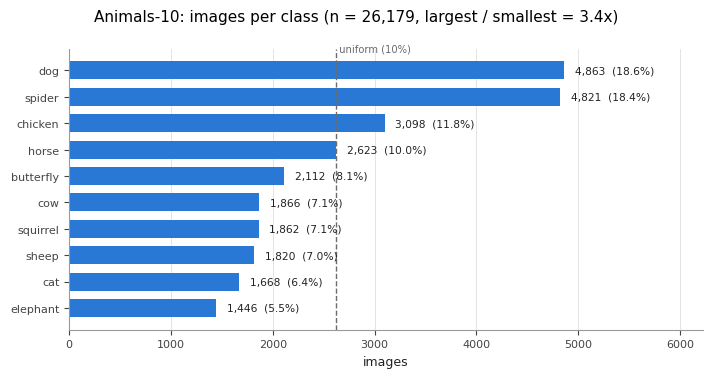

[saved]  animals10_eda/figures/eda_01_class_counts.png
[saved]  animals10_eda/slides/eda_01_class_counts.png
caption: Images per class. The dataset is imbalanced: dog has 4,863 images (18.6%), elephant 1,446 (5.5%), a 3.4x ratio, so macro-averaged metrics are worth reporting next to accuracy.


In [ ]:
cnt = DF["class"].value_counts().reindex(ORDER)
tab = pd.DataFrame({"class": ORDER, "italian_folder": [IT_CLASSES[CLASS_NAMES.index(c)] for c in ORDER],
                    "images": cnt.values, "share_%": 100 * cnt.values / N})
for s in SPLIT_NAMES:
    tab[s] = DF[DF["split"] == s]["class"].value_counts().reindex(ORDER).values
tab.loc[len(tab)] = ["total", "", N, 100.0] + [int((SPLIT == s).sum()) for s in SPLIT_NAMES]
imb = cnt.max() / cnt.min()
KEY.update(n_images=int(N), n_train=int(len(TR)), n_val=int(len(VA)), n_test=int(len(TE)),
           largest_class=ORDER[0], largest_count=int(cnt.iloc[0]),
           smallest_class=ORDER[-1], smallest_count=int(cnt.iloc[-1]), imbalance_ratio=float(imb))
save_table("eda_01_class_counts", tab,
           f"{N} images in 10 classes; {ORDER[0]} is the largest ({cnt.iloc[0]}), {ORDER[-1]} the smallest "
           f"({cnt.iloc[-1]}), imbalance ratio {imb:.2f}:1.")


def fig_class_counts():
    fig, ax = plt.subplots(figsize=(7.2, 3.8))
    y = np.arange(len(ORDER))[::-1]
    ax.barh(y, cnt.values, color=MAIN, height=0.68)
    for yy, v in zip(y, cnt.values):
        ax.text(v + N * 0.004, yy, f"{v:,}  ({100 * v / N:.1f}%)", va="center", fontsize=fs(0.85), color=INK)
    ax.axvline(N / NUM_CLASSES, color=MUTED, lw=1, ls="--")
    ax.text(N / NUM_CLASSES, len(ORDER) - 0.35, " uniform (10%)", color=MUTED, fontsize=fs(0.8), va="bottom")
    ax.set_yticks(y); ax.set_yticklabels(ORDER)
    ax.set_xlim(0, cnt.max() * 1.28); ax.set_xlabel("images")
    ax.grid(axis="x"); ax.set_axisbelow(True)
    fig.suptitle(f"Animals-10: images per class (n = {N:,}, largest / smallest = {imb:.1f}x)")
    fig.tight_layout()
    return fig


save_figure("eda_01_class_counts", fig_class_counts,
            f"Images per class. The dataset is imbalanced: {ORDER[0]} has {cnt.iloc[0]:,} images "
            f"({100 * cnt.iloc[0] / N:.1f}%), {ORDER[-1]} {cnt.iloc[-1]:,} ({100 * cnt.iloc[-1] / N:.1f}%), "
            f"a {imb:.1f}x ratio, so macro-averaged metrics are worth reporting next to accuracy.", deps=STATS_DEPS)

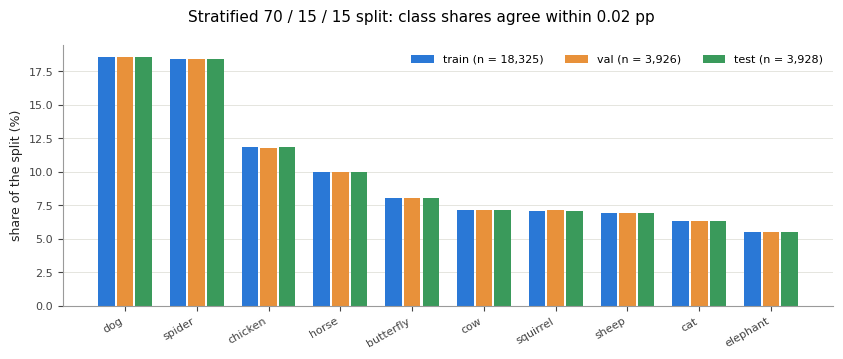

[saved]  animals10_eda/figures/eda_02_split_distribution.png
[saved]  animals10_eda/slides/eda_02_split_distribution.png
caption: Class share in each split. Stratification keeps every class share within 0.02 percentage points across train, validation and test.


In [ ]:
def fig_split_distribution():
    share = (DF.groupby(["split", "class"]).size().unstack(0).reindex(ORDER)[SPLIT_NAMES]
             / DF.groupby("split").size()[SPLIT_NAMES] * 100)
    fig, ax = plt.subplots(figsize=(8.5, 3.6))
    x = np.arange(len(ORDER)); w = 0.26
    for j, s in enumerate(SPLIT_NAMES):
        n_s = int((SPLIT == s).sum())
        ax.bar(x + (j - 1) * w, share[s].values, w - 0.03, color=SPLIT_COLORS[s], label=f"{s} (n = {n_s:,})")
    ax.set_xticks(x); ax.set_xticklabels(ORDER, rotation=30, ha="right")
    ax.set_ylabel("share of the split (%)"); ax.grid(axis="y"); ax.set_axisbelow(True)
    ax.legend(ncol=3, loc="upper right")
    dev = (share.sub(share.mean(1), axis=0)).abs().max().max()
    fig.suptitle(f"Stratified 70 / 15 / 15 split: class shares agree within {dev:.2f} pp")
    fig.tight_layout()
    return fig


_share = (DF.groupby(["split", "class"]).size().unstack(0)[SPLIT_NAMES] / DF.groupby("split").size()[SPLIT_NAMES] * 100)
KEY["split_max_share_dev_pp"] = float(_share.sub(_share.mean(1), axis=0).abs().max().max())
save_figure("eda_02_split_distribution", fig_split_distribution,
            f"Class share in each split. Stratification keeps every class share within "
            f"{KEY['split_max_share_dev_pp']:.2f} percentage points across train, validation and test.",
            deps=STATS_DEPS)

# 6. Example images

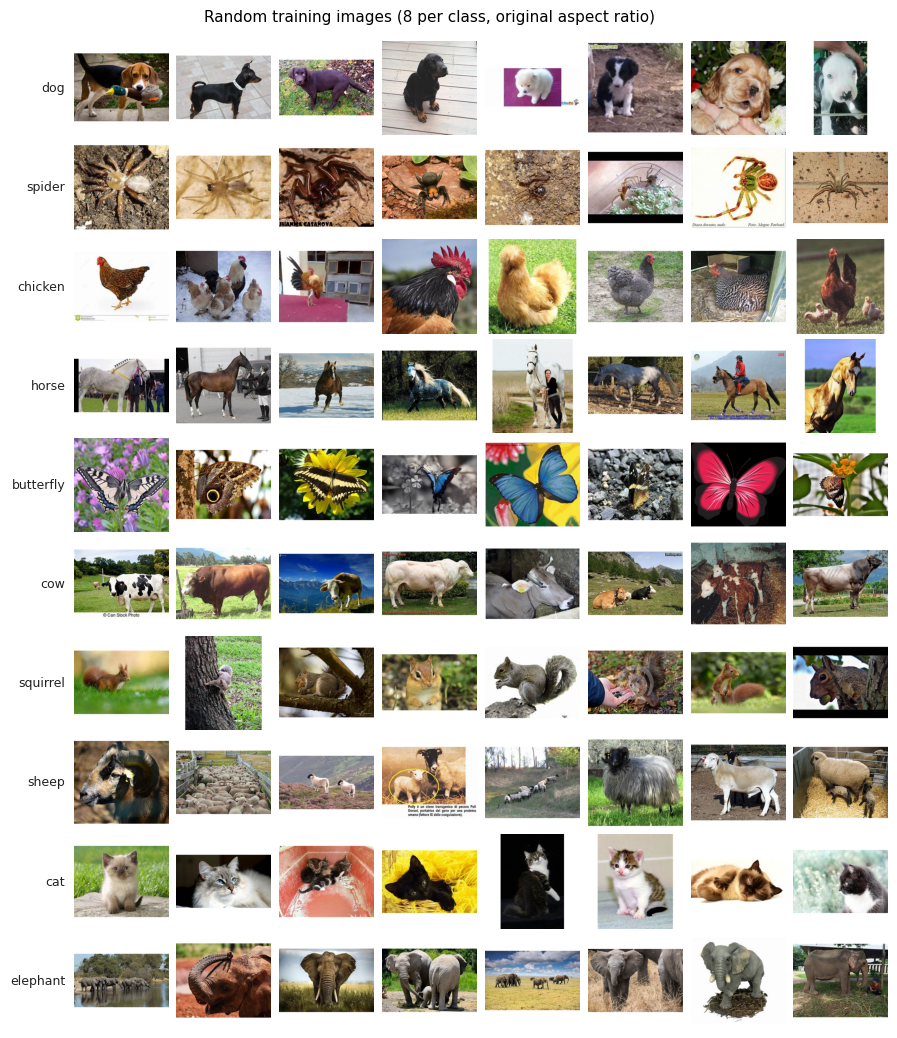

[saved]  animals10_eda/figures/eda_03_sample_grid.png
[saved]  animals10_eda/slides/eda_03_sample_grid.png
caption: Random training images of every class (aspect ratio kept). Images are web photos with varied backgrounds, poses, scales and several animals per picture.


In [ ]:
def fig_sample_grid():
    rng = np.random.default_rng(SEED)
    k = GRID_PER_CLASS
    fig, axes = plt.subplots(NUM_CLASSES, k, figsize=(1.05 * k + 1.0, 1.05 * NUM_CLASSES), squeeze=False)
    for r, c in enumerate(ORDER):
        pool = np.flatnonzero((LABELS == CLASS_NAMES.index(c)) & (SPLIT == "train"))
        for j, i in enumerate(rng.choice(pool, min(k, len(pool)), replace=False)):
            thumb_tile(axes[r, j], open_rgb(PATHS[i], 256))
        for j in range(min(k, len(pool)), k):
            axes[r, j].axis("off")
        axes[r, 0].set_ylabel(c, rotation=0, ha="right", va="center", fontsize=fs(1.0), labelpad=6)
    fig.suptitle(f"Random training images ({k} per class, original aspect ratio)")
    fig.subplots_adjust(wspace=0.05, hspace=0.05, left=0.12, right=0.99, top=0.95, bottom=0.01)
    return fig


save_figure("eda_03_sample_grid", fig_sample_grid,
            "Random training images of every class (aspect ratio kept). Images are web photos with varied "
            "backgrounds, poses, scales and several animals per picture.", deps=STATS_DEPS, width=800)

# 7. Image size, aspect ratio and file size

[saved]  animals10_eda/figures/eda_04_image_size_stats.csv


,measure,count,mean,std,min,5%,50%,95%,max
0,width,26179.000,320.039,196.935,60.000,216.000,300.000,640.000,6720.000
1,height,26179.000,252.630,148.403,57.000,169.000,225.000,426.000,6000.000
2,max_side,26179.000,330.926,201.039,60.000,300.000,300.000,640.000,6720.000
3,aspect,26179.000,1.311,0.311,0.293,0.727,1.333,1.775,4.225
4,megapixels,26179.000,0.106,0.653,0.003,0.051,0.068,0.273,30.106
5,kb,26179.000,22.917,108.143,1.421,6.939,13.214,70.003,5443.841


Most common sizes:
 width  height
300    225       4397
       200       3281
       300       1192
       169       1048
640    426        694
dtype: int64


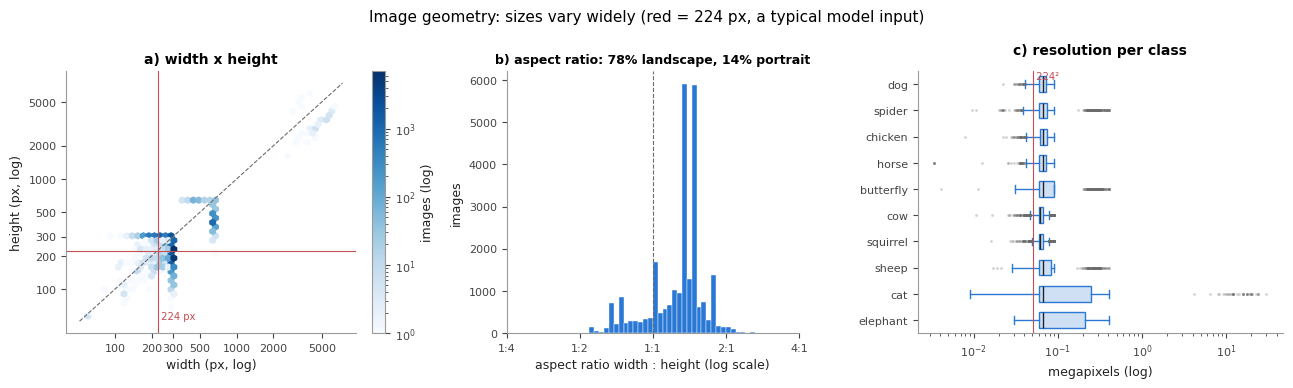

[saved]  animals10_eda/figures/eda_04_image_sizes.png
[saved]  animals10_eda/slides/eda_04_image_sizes.png
caption: Image geometry. Sizes vary widely (median 300 x 225 px, 90% with a 300 px longest side); 78% are landscape, 14% portrait; only 54% have both sides >= 224 px; the others are upsampled in at least one direction by the 224 x 224 resize.


In [ ]:
q = DF[["width", "height", "max_side", "aspect", "megapixels", "kb"]].describe(percentiles=[.05, .5, .95]).T
q.insert(0, "measure", q.index)
common = DF.groupby(["width", "height"]).size().sort_values(ascending=False).head(5)
KEY.update(median_width=float(DF["width"].median()), median_height=float(DF["height"].median()),
           max_side_300_share=float((DF["max_side"] == 300).mean()),
           landscape_share=float((DF["aspect"] > 1.05).mean()), portrait_share=float((DF["aspect"] < 0.95).mean()),
           square_share=float(((DF["aspect"] >= 0.95) & (DF["aspect"] <= 1.05)).mean()),
           min_side_below_100=int((DF[["width", "height"]].min(1) < 100).sum()),
           larger_than_224_share=float((DF[["width", "height"]].min(1) >= IMG_SIZE).mean()))
save_table("eda_04_image_size_stats", q.reset_index(drop=True).round(3),
           f"Image size statistics. Median {KEY['median_width']:.0f} x {KEY['median_height']:.0f} px; "
           f"{100 * KEY['max_side_300_share']:.0f}% of the images have a longest side of exactly 300 px.")
print("Most common sizes:\n", common)


def fig_image_sizes():
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1.1, 1, 1.25]})
    ax = axes[0]
    hb = ax.hexbin(DF["width"], DF["height"], gridsize=45, bins="log", cmap="Blues", mincnt=1,
                   xscale="log", yscale="log")
    lim = [max(10, DF[["width", "height"]].min().min() * 0.9), DF[["width", "height"]].max().max() * 1.1]
    ax.plot(lim, lim, color=MUTED, lw=0.8, ls="--")
    ax.axvline(IMG_SIZE, color="#c44e52", lw=0.8); ax.axhline(IMG_SIZE, color="#c44e52", lw=0.8)
    ax.text(IMG_SIZE, lim[0] * 1.05, f" {IMG_SIZE} px", color="#c44e52", fontsize=fs(0.8))
    _t = [t for t in (25, 50, 100, 200, 300, 500, 1000, 2000, 5000) if lim[0] <= t <= lim[1]]
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(matplotlib.ticker.FixedLocator(_t))
        axis.set_major_formatter(matplotlib.ticker.FixedFormatter([str(t) for t in _t]))
        axis.set_minor_locator(matplotlib.ticker.NullLocator())
    ax.set_xlabel("width (px, log)"); ax.set_ylabel("height (px, log)")
    ax.set_title("a) width x height")
    fig.colorbar(hb, ax=ax, label="images (log)", fraction=0.05)
    ax = axes[1]
    ar = np.log2(DF["aspect"].clip(1 / 8, 8))
    ax.hist(ar, bins=np.linspace(-2, 2, 61), color=MAIN, edgecolor="white", linewidth=0.3)
    ax.axvline(0, color=MUTED, lw=0.8, ls="--")
    ticks = [1 / 4, 1 / 2, 1, 2, 4]
    ax.set_xticks(np.log2(ticks)); ax.set_xticklabels(["1:4", "1:2", "1:1", "2:1", "4:1"])
    ax.set_xlim(-2, 2); ax.set_xlabel("aspect ratio width : height (log scale)"); ax.set_ylabel("images")
    ax.set_title(f"b) aspect ratio: {100 * KEY['landscape_share']:.0f}% landscape, "
                 f"{100 * KEY['portrait_share']:.0f}% portrait", fontsize=fs(1.0))
    ax = axes[2]
    data = [DF.loc[DF["class"] == c, "megapixels"].values for c in ORDER]
    bp = ax.boxplot(data, vert=False, widths=0.6, showfliers=True, patch_artist=True,
                    flierprops=dict(marker=".", ms=2, alpha=0.3, mec=MUTED),
                    medianprops=dict(color=INK), boxprops=dict(facecolor="#cfe0f5", edgecolor=MAIN),
                    whiskerprops=dict(color=MAIN), capprops=dict(color=MAIN))
    ax.set_yticks(range(1, len(ORDER) + 1)); ax.set_yticklabels(ORDER); ax.invert_yaxis()
    ax.set_xscale("log"); ax.axvline(IMG_SIZE ** 2 / 1e6, color="#c44e52", lw=0.8)
    ax.text(IMG_SIZE ** 2 / 1e6, 1.0, f" {IMG_SIZE}²", color="#c44e52", fontsize=fs(0.8), va="top",
            transform=ax.get_xaxis_transform())
    ax.set_xlabel("megapixels (log)"); ax.set_title("c) resolution per class", pad=12)
    fig.suptitle(f"Image geometry: sizes vary widely (red = {IMG_SIZE} px, a typical model input)")
    fig.tight_layout()
    return fig


save_figure("eda_04_image_sizes", fig_image_sizes,
            f"Image geometry. Sizes vary widely (median {KEY['median_width']:.0f} x {KEY['median_height']:.0f} px, "
            f"{100 * KEY['max_side_300_share']:.0f}% with a 300 px longest side); "
            f"{100 * KEY['landscape_share']:.0f}% are landscape, {100 * KEY['portrait_share']:.0f}% portrait; only "
            f"{100 * KEY['larger_than_224_share']:.0f}% have both sides >= 224 px; the others are upsampled "
            f"in at least one direction by the 224 x 224 resize.", deps=STATS_DEPS, width=1100)

[saved]  animals10_eda/figures/eda_05_formats.csv


,format,mode,images,share_%
2,JPEG,RGB,26126,99.798
4,PNG,RGBA,49,0.187
3,PNG,RGB,2,0.008
0,JPEG,CMYK,1,0.004
1,JPEG,L,1,0.004


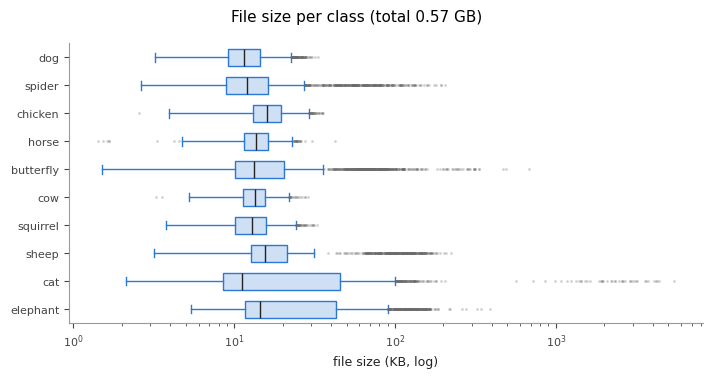

[saved]  animals10_eda/figures/eda_05_file_size.png
[saved]  animals10_eda/slides/eda_05_file_size.png
caption: File size per class; the whole dataset is 0.57 GB.


In [ ]:
fmt = (DF.groupby(["format", "mode"]).size().rename("images").reset_index()
       .sort_values("images", ascending=False))
fmt["share_%"] = 100 * fmt["images"] / N
KEY.update(formats=fmt.groupby("format")["images"].sum().to_dict(),
           non_rgb_mode=int((DF["mode"] != "RGB").sum()), gray_content=int(DF["gray_content"].sum()))
save_table("eda_05_formats", fmt,
           f"File formats and colour modes; {KEY['non_rgb_mode']} files are not stored as RGB and "
           f"{KEY['gray_content']} RGB-or-other images have grayscale content; all are converted to RGB.")


def fig_file_size():
    fig, ax = plt.subplots(figsize=(7.2, 3.8))
    data = [DF.loc[DF["class"] == c, "kb"].values for c in ORDER]
    ax.boxplot(data, vert=False, widths=0.6, patch_artist=True,
               flierprops=dict(marker=".", ms=2, alpha=0.3, mec=MUTED), medianprops=dict(color=INK),
               boxprops=dict(facecolor="#cfe0f5", edgecolor=MAIN), whiskerprops=dict(color=MAIN),
               capprops=dict(color=MAIN))
    ax.set_yticks(range(1, len(ORDER) + 1)); ax.set_yticklabels(ORDER); ax.invert_yaxis()
    ax.set_xscale("log"); ax.set_xlabel("file size (KB, log)")
    ax.set_title("")
    fig.suptitle(f"File size per class (total {DF['file_bytes'].sum() / 2 ** 30:.2f} GB)")
    fig.tight_layout()
    return fig


save_figure("eda_05_file_size", fig_file_size,
            f"File size per class; the whole dataset is {DF['file_bytes'].sum() / 2 ** 30:.2f} GB.", deps=STATS_DEPS)

# 8. Effect of the 224 x 224 resize
A common preprocessing is to resize every image to 224 x 224 without cropping
(`transforms.Resize((224, 224))`), which does not keep the aspect ratio. The most elongated images show how strong the distortion can be.

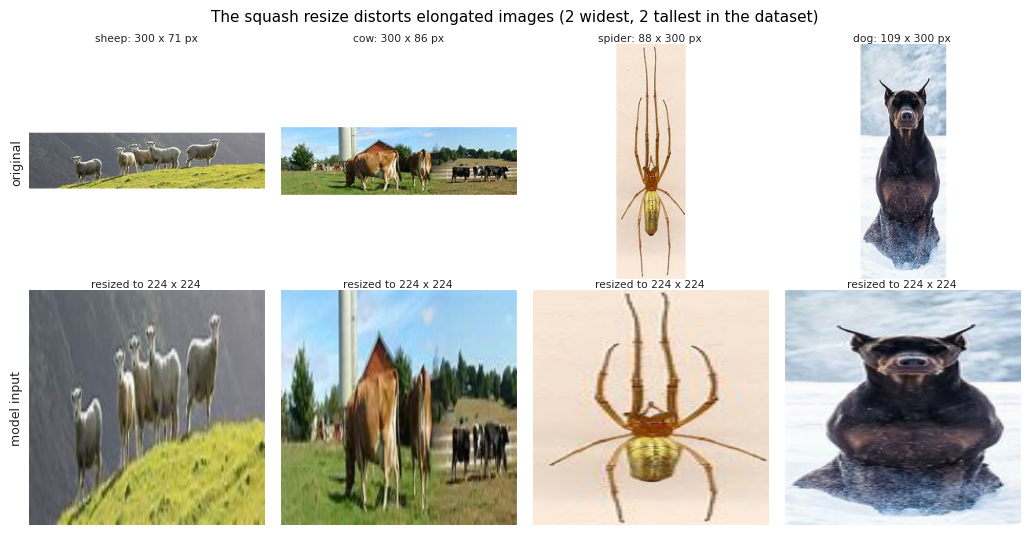

[saved]  animals10_eda/figures/eda_06_resize_effect.png
[saved]  animals10_eda/slides/eda_06_resize_effect.png
caption: Original image (top) and the 224 x 224 model input (bottom) for the most elongated images: the squash resize keeps the whole animal but changes its shape.


In [ ]:
def fig_resize_effect(n=4):
    la = np.log(DF["aspect"].values)
    pick = list(np.argsort(-la)[: n // 2]) + list(np.argsort(la)[: n - n // 2])   # widest, tallest
    fig, axes = plt.subplots(2, n, figsize=(2.6 * n, 5.4), squeeze=False)
    for j, i in enumerate(pick):
        im = open_rgb(PATHS[i])
        r = DF.loc[i]
        thumb_tile(axes[0, j], im, f"{r['class']}: {r['width']} x {r['height']} px", fs_k=0.85)
        thumb_tile(axes[1, j], im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), f"resized to {IMG_SIZE} x {IMG_SIZE}",
                   pad=False, fs_k=0.85)
    axes[0, 0].set_ylabel("original", fontsize=fs(1.0)); axes[1, 0].set_ylabel("model input", fontsize=fs(1.0))
    fig.suptitle("The squash resize distorts elongated images (2 widest, 2 tallest in the dataset)")
    fig.tight_layout()
    return fig


save_figure("eda_06_resize_effect", fig_resize_effect,
            "Original image (top) and the 224 x 224 model input (bottom) for the most elongated images: the squash "
            "resize keeps the whole animal but changes its shape.", deps=STATS_DEPS, width=900)

# 9. Colour: mean image and hue per class

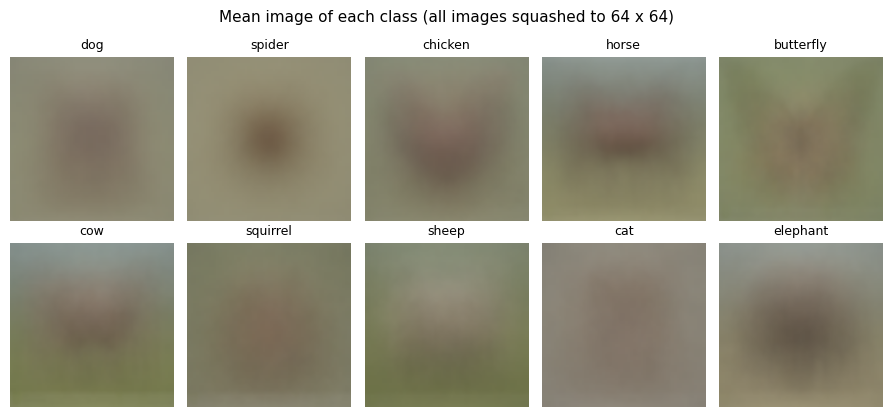

[saved]  animals10_eda/figures/eda_07_mean_images.png
[saved]  animals10_eda/slides/eda_07_mean_images.png
caption: Mean image per class (64 x 64). Shape is averaged away; what remains is the typical colour and brightness layout (subject vs background) of each class.


In [ ]:
MEAN_IMG = np.stack([THUMBS[LABELS == CLASS_NAMES.index(c)].astype(np.float64).mean(0) for c in ORDER])


def fig_mean_images():
    fig, axes = plt.subplots(2, 5, figsize=(9, 4.3))
    for ax, c, m in zip(axes.flat, ORDER, MEAN_IMG):
        ax.imshow(m.astype(np.uint8), interpolation="bilinear")
        ax.set_title(c, fontsize=fs(1.0), fontweight="normal"); ax.axis("off")
    fig.suptitle("Mean image of each class (all images squashed to 64 x 64)")
    fig.tight_layout()
    return fig


save_figure("eda_07_mean_images", fig_mean_images,
            "Mean image per class (64 x 64). Shape is averaged away; what remains is the typical colour and "
            "brightness layout (subject vs background) of each class.", deps=STATS_DEPS, width=850)

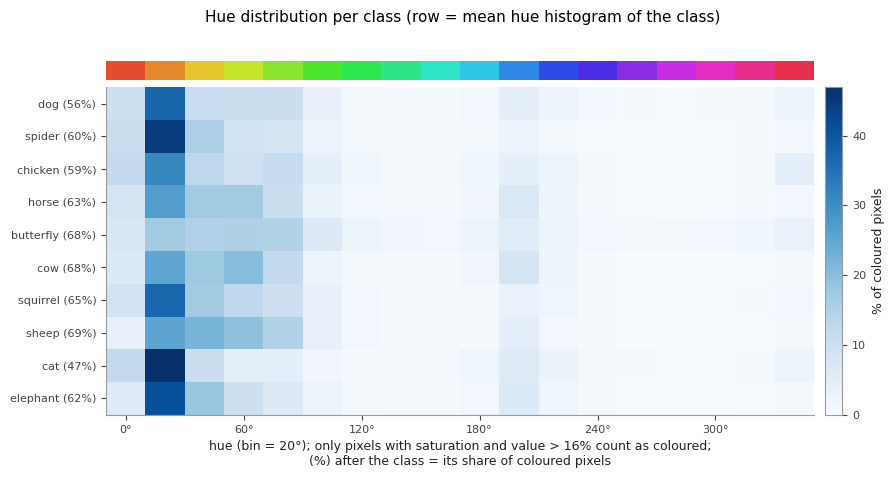

[saved]  animals10_eda/figures/eda_08_hue_by_class.png
[saved]  animals10_eda/slides/eda_08_hue_by_class.png
caption: Hue histogram per class. Over the whole dataset the most frequent hue is 20-40°; butterfly, sheep, chicken have the largest green (80-160°) share (25%, 20%, 18%), i.e. colour, largely from the background, differs between classes and is a cue the HSV-histogram features can use.


In [ ]:
HUE_COLS = [f"hue_{b:02d}" for b in range(HUE_BINS)]
HUE_MAT = np.stack([DF.loc[DF["class"] == c, HUE_COLS].mean().values for c in ORDER]) * 100


def fig_hue_by_class():
    fig = plt.figure(figsize=(9.5, 4.6))
    gs = fig.add_gridspec(2, 2, height_ratios=[0.06, 1], width_ratios=[1, 0.025], hspace=0.04, wspace=0.03)
    ax = fig.add_subplot(gs[1, 0]); strip = fig.add_subplot(gs[0, 0], sharex=ax); cax = fig.add_subplot(gs[1, 1])
    im = ax.imshow(HUE_MAT, cmap="Blues", aspect="auto", vmin=0)
    cf = DF.groupby("class")["colored_frac"].mean().reindex(ORDER) * 100
    ax.set_yticks(range(len(ORDER))); ax.set_yticklabels([f"{c} ({v:.0f}%)" for c, v in zip(ORDER, cf.values)])
    deg = np.arange(HUE_BINS) * 360 / HUE_BINS
    ax.set_xticks(np.arange(HUE_BINS)[::3]); ax.set_xticklabels([f"{d:.0f}°" for d in deg[::3]])
    ax.set_xlabel("hue (bin = 20°); only pixels with saturation and value > 16% count as coloured;\n"
                  "(%) after the class = its share of coloured pixels")
    hue_rgb = mcolors.hsv_to_rgb(np.stack([(np.arange(HUE_BINS) + 0.5) / HUE_BINS,
                                           np.full(HUE_BINS, 0.8), np.full(HUE_BINS, 0.9)], 1))
    strip.imshow(hue_rgb[None], aspect="auto"); strip.axis("off")
    fig.colorbar(im, cax=cax, label="% of coloured pixels")
    fig.suptitle("Hue distribution per class (row = mean hue histogram of the class)", y=0.99)
    return fig


_green = HUE_MAT[:, 4:8].sum(1)            # bins 80-160 deg
_top_green = [ORDER[i] for i in np.argsort(-_green)[:3]]
_all_hue = DF[HUE_COLS].mean().values
_hb = int(np.argmax(_all_hue))
KEY.update(greenest_classes=_top_green, dominant_hue_deg=[_hb * 20, _hb * 20 + 20],
           green_share_pct={c: float(g) for c, g in zip(ORDER, _green)})
save_figure("eda_08_hue_by_class", fig_hue_by_class,
            f"Hue histogram per class. Over the whole dataset the most frequent hue is {_hb * 20}-{_hb * 20 + 20}°; "
            f"{', '.join(_top_green)} have the largest green (80-160°) share "
            f"({', '.join(f'{_green[ORDER.index(c)]:.0f}%' for c in _top_green)}), i.e. colour, largely from the "
            f"background, differs between classes and is a cue the HSV-histogram features can use.", deps=STATS_DEPS, width=950)

# 10. Image quality: brightness, contrast, colourfulness, sharpness

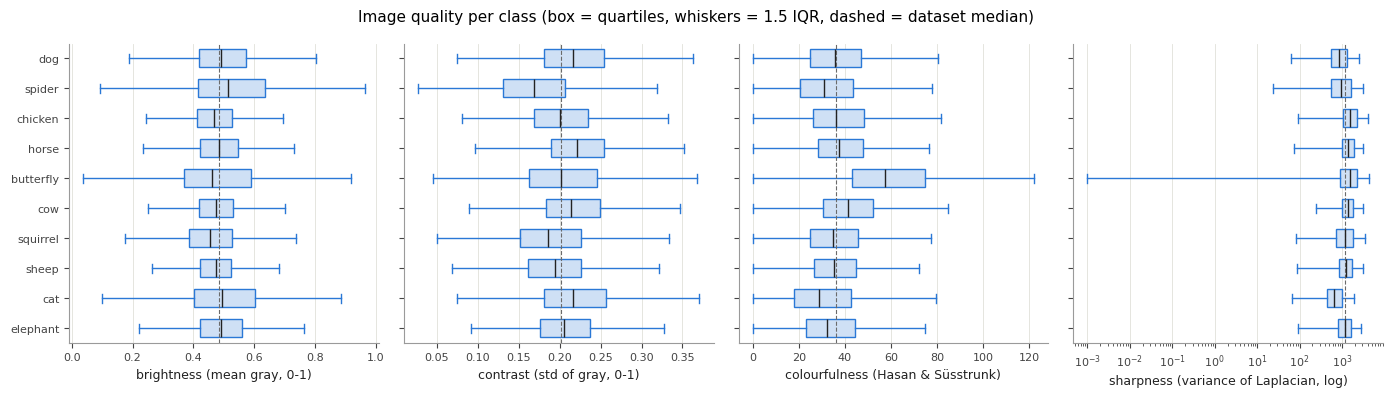

[saved]  animals10_eda/figures/eda_09_image_quality.png
[saved]  animals10_eda/slides/eda_09_image_quality.png
caption: Low-level image statistics per class (on the 128 x 128 squashed image). butterfly images are the most colourful and cat the least; chicken are the sharpest, cat the blurriest (median). The distributions overlap heavily, so no single statistic separates the classes.


In [ ]:
QUAL = [("brightness", "brightness (mean gray, 0-1)", False), ("contrast", "contrast (std of gray, 0-1)", False),
        ("colorfulness", "colourfulness (Hasan & Süsstrunk)", False),
        ("sharpness", "sharpness (variance of Laplacian, log)", True)]


def fig_image_quality():
    fig, axes = plt.subplots(1, 4, figsize=(14, 4.0), sharey=True)
    for ax, (col, label, log) in zip(axes, QUAL):
        data = [np.clip(DF.loc[DF["class"] == c, col].values, 1e-3, None) for c in ORDER]
        ax.boxplot(data, vert=False, widths=0.6, patch_artist=True, showfliers=False,
                   medianprops=dict(color=INK), boxprops=dict(facecolor="#cfe0f5", edgecolor=MAIN),
                   whiskerprops=dict(color=MAIN), capprops=dict(color=MAIN))
        med = np.median(np.clip(DF[col].values, 1e-3, None))
        ax.axvline(med, color=MUTED, lw=0.8, ls="--")
        if log:
            ax.set_xscale("log")
        ax.set_xlabel(label); ax.grid(axis="x"); ax.set_axisbelow(True)
    axes[0].set_yticks(range(1, len(ORDER) + 1)); axes[0].set_yticklabels(ORDER); axes[0].invert_yaxis()
    fig.suptitle("Image quality per class (box = quartiles, whiskers = 1.5 IQR, dashed = dataset median)")
    fig.tight_layout()
    return fig


_qm = DF.groupby("class")[["brightness", "colorfulness", "sharpness"]].median().reindex(ORDER)
KEY.update(brightest_class=_qm["brightness"].idxmax(), darkest_class=_qm["brightness"].idxmin(),
           most_colourful_class=_qm["colorfulness"].idxmax(), least_colourful_class=_qm["colorfulness"].idxmin(),
           sharpest_class=_qm["sharpness"].idxmax(), blurriest_class=_qm["sharpness"].idxmin())
save_figure("eda_09_image_quality", fig_image_quality,
            f"Low-level image statistics per class (on the 128 x 128 squashed image). {KEY['most_colourful_class']} "
            f"images are the most colourful and {KEY['least_colourful_class']} the least; "
            f"{KEY['sharpest_class']} are the sharpest, {KEY['blurriest_class']} the blurriest (median). The "
            f"distributions overlap heavily, so no single statistic separates the classes.",
            deps=STATS_DEPS, width=1100)

# 11. Pixel intensities and normalization statistics
The dataset mean / std per channel are computed on the training split (128 x 128 images, every image
weighted equally) and compared with the ImageNet statistics that the pretrained models normalize with.

[saved]  animals10_eda/figures/eda_10_normalization.csv


,channel,animals10_train_mean,animals10_train_std,imagenet_mean,imagenet_std
0,R,0.518,0.262,0.485,0.229
1,G,0.500,0.257,0.456,0.224
2,B,0.412,0.275,0.406,0.225


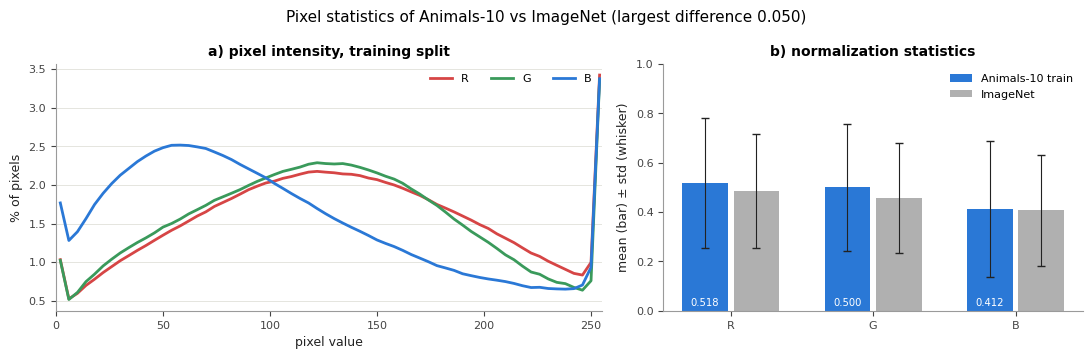

[saved]  animals10_eda/figures/eda_10_rgb_histogram.png
[saved]  animals10_eda/slides/eda_10_rgb_histogram.png
caption: Pixel-intensity histogram of the training images and per-channel mean / std compared with ImageNet.


In [ ]:
tr_df = DF[DF["split"] == "train"]
mean_c = np.array([tr_df[f"mean_{c}"].mean() for c in "rgb"])
std_c = np.sqrt(np.array([tr_df[f"sq_{c}"].mean() for c in "rgb"]) - mean_c ** 2)
IMNET_MEAN, IMNET_STD = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
norm_tab = pd.DataFrame({"channel": ["R", "G", "B"], "animals10_train_mean": mean_c, "animals10_train_std": std_c,
                         "imagenet_mean": IMNET_MEAN, "imagenet_std": IMNET_STD})
_dev = float(max(np.abs(mean_c - IMNET_MEAN).max(), np.abs(std_c - IMNET_STD).max()))
KEY.update(train_mean_rgb=mean_c.round(4).tolist(), train_std_rgb=std_c.round(4).tolist(), max_dev_from_imagenet=_dev)
save_table("eda_10_normalization", norm_tab,
           f"Per-channel mean / std of the training images ({', '.join(f'{v:.3f}' for v in mean_c)} / "
           f"{', '.join(f'{v:.3f}' for v in std_c)}); they differ from the ImageNet statistics used by the pretrained "
           f"models by at most {_dev:.3f}.")


def pixel_hist(idx, bins=64, size=64):
    """Per-channel intensity histogram of the 64x64 thumbnails of `idx`."""
    t = THUMBS[idx].reshape(-1, 3)
    return np.stack([np.bincount(t[:, k] // (256 // bins), minlength=bins) for k in range(3)]) / len(t)


def fig_rgb_histogram():
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
    ax = axes[0]
    h = pixel_hist(TR)
    x = (np.arange(64) + 0.5) * 4
    for k, (c, col) in enumerate(zip("RGB", ["#d64545", "#3a9a5b", "#2a78d6"])):
        ax.plot(x, h[k] * 100, color=col, lw=2, label=c)
    ax.set_xlim(0, 255); ax.set_xlabel("pixel value"); ax.set_ylabel("% of pixels")
    ax.legend(ncol=3); ax.set_title("a) pixel intensity, training split"); ax.grid(axis="y"); ax.set_axisbelow(True)
    ax = axes[1]
    xx = np.arange(3); w = 0.36
    ax.bar(xx - w / 2, mean_c, w - 0.04, color=MAIN, label="Animals-10 train",
           yerr=std_c, capsize=3, error_kw=dict(ecolor=INK, lw=0.8))
    ax.bar(xx + w / 2, IMNET_MEAN, w - 0.04, color="#b0b0b0", label="ImageNet",
           yerr=IMNET_STD, capsize=3, error_kw=dict(ecolor=INK, lw=0.8))
    for x0, m in zip(xx - w / 2, mean_c):
        ax.text(x0, 0.02, f"{m:.3f}", ha="center", fontsize=fs(0.8), color="white")
    ax.set_xticks(xx); ax.set_xticklabels(["R", "G", "B"]); ax.set_ylim(0, 1)
    ax.set_ylabel("mean (bar) ± std (whisker)"); ax.legend(loc="upper right")
    ax.set_title("b) normalization statistics")
    fig.suptitle(f"Pixel statistics of Animals-10 vs ImageNet (largest difference {_dev:.3f})")
    fig.tight_layout()
    return fig


save_figure("eda_10_rgb_histogram", fig_rgb_histogram,
            "Pixel-intensity histogram of the training images and per-channel mean / std compared with ImageNet.",
            deps=STATS_DEPS, width=1000)

# 12. Duplicates: data leakage across splits and label conflicts
* **exact**: identical file bytes (MD5);
* **near**: 64-bit dHash differing in at most `DUP_HAMMING` bits (re-encoded, resized or lightly edited copies).

A near-duplicate pair with one image in train and the other in test inflates the test score
(leakage); a pair with two different labels is label noise. Pairs are counted once.

dHash pairs:   0%|          | 0/52 [00:00<?, ?it/s]

[saved]  animals10_eda/figures/eda_11_duplicates.csv


,measure,value
0,"exact duplicate files (extra copies, MD5)",0.000
1,"near-duplicate pairs (dHash <= 4 bits), incl. ...",2156.000
2,images in at least one near-duplicate pair,2844.000
3,pairs train-train,1058.000
4,pairs train-val,441.000
5,pairs train-test,471.000
6,pairs val-val,34.000
7,pairs val-test,101.000
8,pairs test-test,51.000
9,test images with a near duplicate in train,344.000


,count
splits,
train-train,1058
train-test,471
train-val,441
val-test,101
test-test,51
val-val,34


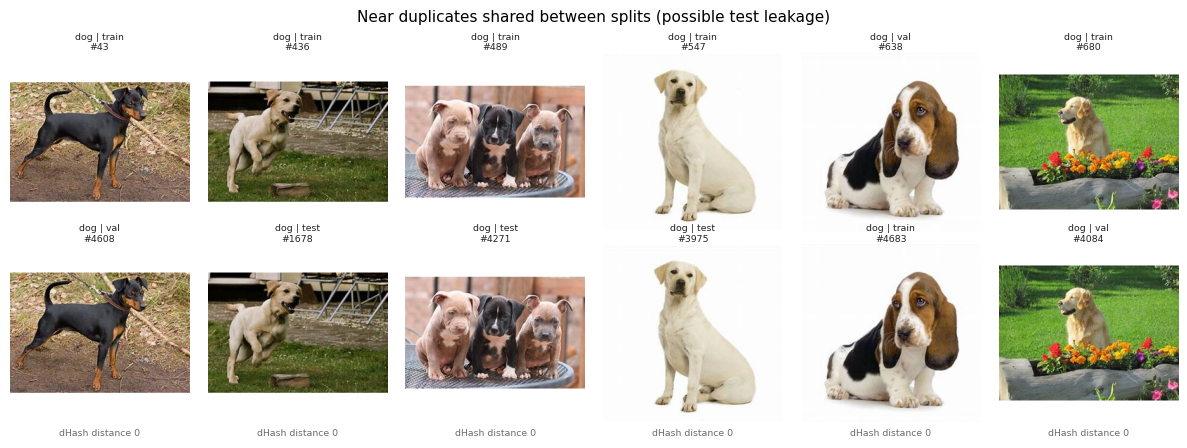

[saved]  animals10_eda/figures/eda_11_duplicates_cross_split.png
[saved]  animals10_eda/slides/eda_11_duplicates_cross_split.png
caption: Examples of near-duplicate pairs that fall in different splits. 344 test images (8.8% of the test split) have a near copy in train, which can slightly inflate test scores for every model alike.


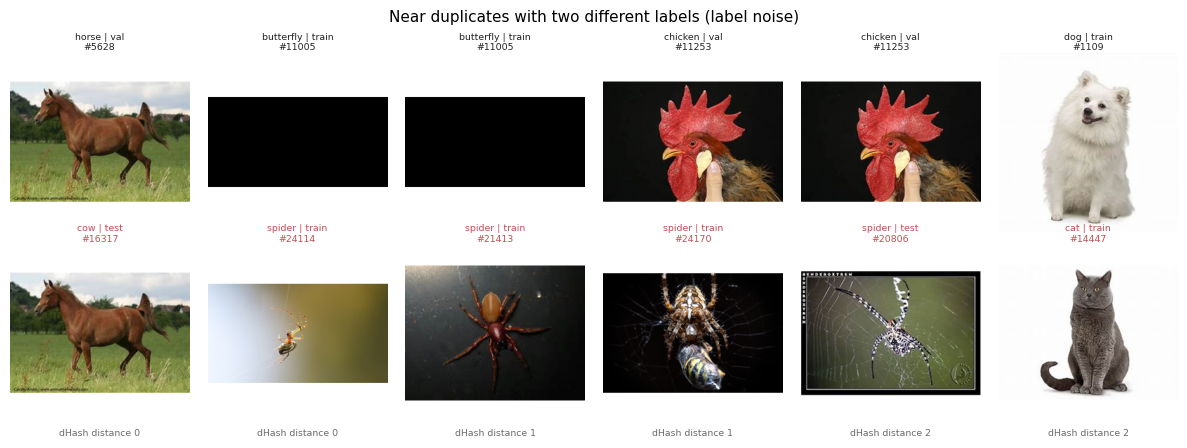

[saved]  animals10_eda/figures/eda_11_duplicates_cross_class.png
[saved]  animals10_eda/slides/eda_11_duplicates_cross_class.png
caption: Near-duplicate pairs with conflicting labels (102 pair(s)); red = the second label.


In [ ]:
def popcount64(x):
    x = x - ((x >> np.uint64(1)) & np.uint64(0x5555555555555555))
    x = (x & np.uint64(0x3333333333333333)) + ((x >> np.uint64(2)) & np.uint64(0x3333333333333333))
    x = (x + (x >> np.uint64(4))) & np.uint64(0x0F0F0F0F0F0F0F0F)
    return (x * np.uint64(0x0101010101010101)) >> np.uint64(56)


def near_pairs(hashes, thr, chunk=512):
    """All pairs (i < j) with Hamming distance <= thr between 64-bit hashes."""
    h = np.array([int(s, 16) for s in hashes], dtype=np.uint64)
    out = []
    for s in tqdm(range(0, len(h), chunk), desc="dHash pairs"):
        d = popcount64(h[s:s + chunk, None] ^ h[None, :])
        i, j = np.nonzero(d <= thr)
        i = i + s
        keep = j > i
        out.append(np.stack([i[keep], j[keep], d[i[keep] - s, j[keep]]], 1))
    return np.concatenate(out).astype(np.int64) if out else np.zeros((0, 3), np.int64)


DUP_CACHE = os.path.join(CACHE_DIR, f"dup_pairs_h{DUP_HAMMING}.npy")
if needs_build(DUP_CACHE, "dup_pairs", STATS_DEPS):
    PAIRS = near_pairs(DF["dhash"].values, DUP_HAMMING)
    np.save(DUP_CACHE, PAIRS)
else:
    PAIRS = np.load(DUP_CACHE)

pairs = pd.DataFrame(PAIRS, columns=["i", "j", "hamming"])
pairs["exact"] = DF["md5"].values[pairs["i"]] == DF["md5"].values[pairs["j"]]
pairs["split_i"], pairs["split_j"] = SPLIT[pairs["i"]], SPLIT[pairs["j"]]
pairs["class_i"], pairs["class_j"] = DF["class"].values[pairs["i"]], DF["class"].values[pairs["j"]]
pairs["cross_split"] = pairs["split_i"] != pairs["split_j"]
pairs["cross_class"] = pairs["class_i"] != pairs["class_j"]
pairs["splits"] = ["-".join(sorted([a, b], key=SPLIT_NAMES.index)) for a, b in zip(pairs["split_i"], pairs["split_j"])]
# exact copies whose dHash differs by more than the threshold cannot exist (same bytes = same hash)
md5_groups = DF.groupby("md5").size()
n_exact_files = int((md5_groups[md5_groups > 1] - 1).sum())

in_pair = np.zeros(N, bool); in_pair[pairs["i"]] = True; in_pair[pairs["j"]] = True
test_leak = set()
for a, b, sa, sb in zip(pairs["i"], pairs["j"], pairs["split_i"], pairs["split_j"]):
    if sa == "test" and sb == "train":
        test_leak.add(a)
    if sb == "test" and sa == "train":
        test_leak.add(b)
dup_tab = pd.DataFrame([
    {"measure": "exact duplicate files (extra copies, MD5)", "value": n_exact_files},
    {"measure": f"near-duplicate pairs (dHash <= {DUP_HAMMING} bits), incl. exact", "value": len(pairs)},
    {"measure": "images in at least one near-duplicate pair", "value": int(in_pair.sum())},
    *[{"measure": f"pairs {s}", "value": int((pairs["splits"] == s).sum())}
      for s in ["train-train", "train-val", "train-test", "val-val", "val-test", "test-test"]],
    {"measure": "test images with a near duplicate in train", "value": len(test_leak)},
    {"measure": "  share of the test split (%)", "value": round(100 * len(test_leak) / len(TE), 2)},
    {"measure": "pairs with two different labels", "value": int(pairs["cross_class"].sum())},
])
KEY.update(exact_duplicate_files=n_exact_files, near_duplicate_pairs=int(len(pairs)),
           test_images_with_train_duplicate=len(test_leak),
           test_leak_share=float(len(test_leak) / len(TE)), cross_class_pairs=int(pairs["cross_class"].sum()))
save_table("eda_11_duplicates", dup_tab,
           f"{n_exact_files} exact duplicate file(s) and {len(pairs)} near-duplicate pair(s); {len(test_leak)} test "
           f"images ({100 * len(test_leak) / len(TE):.1f}%) have a near duplicate in the training split, and "
           f"{int(pairs['cross_class'].sum())} pair(s) carry two different labels.")
pairs.assign(path_i=DF["path"].values[pairs["i"]], path_j=DF["path"].values[pairs["j"]]) \
     .to_csv(os.path.join(EDA_DIR, "eda_11_duplicate_pairs.csv"), index=False)
display(pairs["splits"].value_counts())


def fig_dup_pairs(sel, title, n=6):
    sel = sel.head(n)
    if len(sel) == 0:
        fig, ax = plt.subplots(figsize=(6, 1.2)); ax.axis("off")
        ax.text(0.5, 0.5, "no such pair found", ha="center", va="center", fontsize=fs(1.1))
        fig.suptitle(title)
        return fig
    fig, axes = plt.subplots(2, len(sel), figsize=(1.9 * len(sel) + 0.6, 4.4), squeeze=False)
    for j, r in enumerate(sel.itertuples()):
        for row, (i, s, c) in enumerate([(r.i, r.split_i, r.class_i), (r.j, r.split_j, r.class_j)]):
            col = "#c44e52" if (r.cross_class and row == 1) else INK
            thumb_tile(axes[row, j], open_rgb(PATHS[i], 256), f"{c} | {s}\n#{i}", color=col, fs_k=0.75)
        axes[1, j].set_xlabel("identical file" if r.exact else f"dHash distance {r.hamming}",
                              fontsize=fs(0.75), color=MUTED)
    fig.suptitle(title)
    fig.tight_layout()
    return fig


_leak = pairs[pairs["splits"].isin(["train-test", "train-val", "val-test"])].sort_values(["hamming", "exact"],
                                                                                         ascending=[True, False])
save_figure("eda_11_duplicates_cross_split",
            lambda: fig_dup_pairs(_leak, "Near duplicates shared between splits (possible test leakage)"),
            f"Examples of near-duplicate pairs that fall in different splits. {len(test_leak)} test images "
            f"({100 * len(test_leak) / len(TE):.1f}% of the test split) have a near copy in train, which can "
            f"slightly inflate test scores for every model alike.", deps=[DUP_CACHE], width=900)
save_figure("eda_11_duplicates_cross_class",
            lambda: fig_dup_pairs(pairs[pairs["cross_class"]].sort_values("hamming"),
                                  "Near duplicates with two different labels (label noise)"),
            f"Near-duplicate pairs with conflicting labels ({int(pairs['cross_class'].sum())} pair(s)); "
            f"red = the second label.", deps=[DUP_CACHE], width=900)

# 13. Outliers worth a look

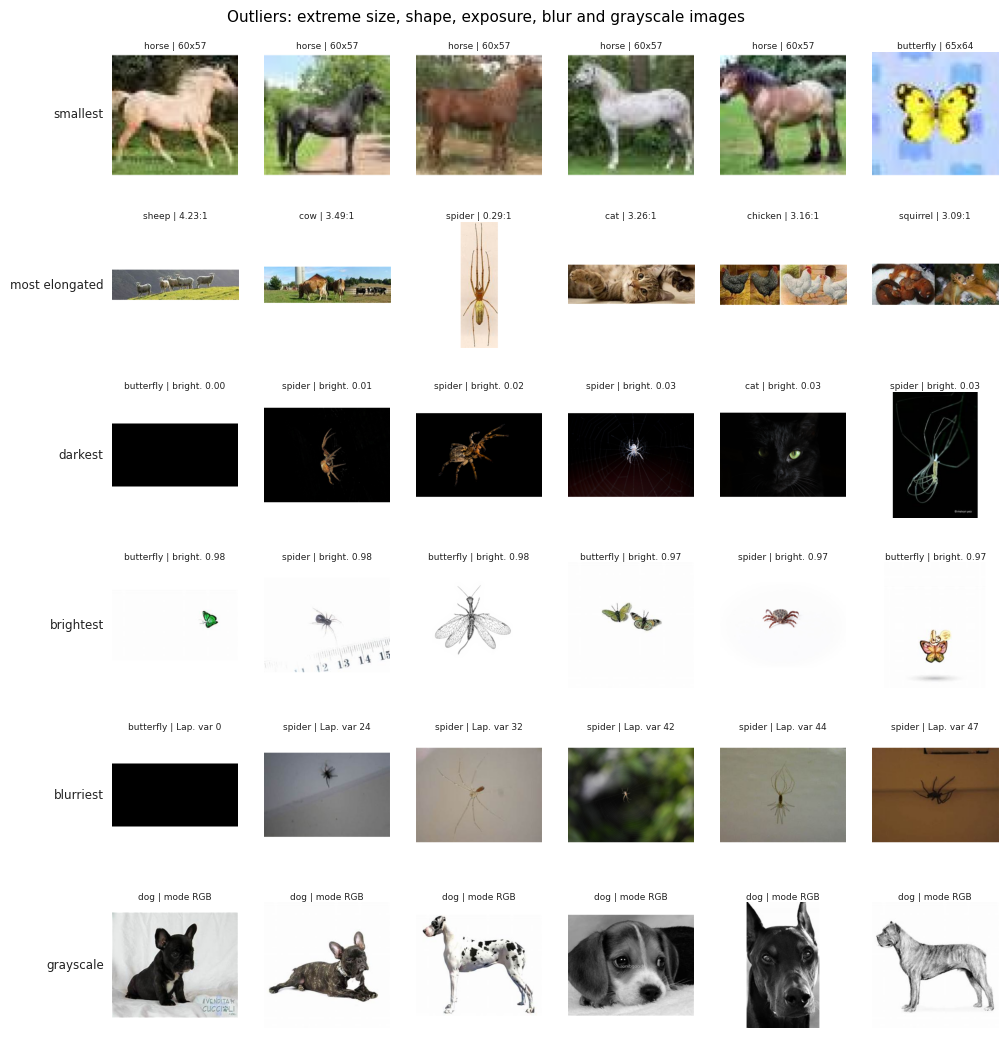

[saved]  animals10_eda/figures/eda_12_outliers.png
[saved]  animals10_eda/slides/eda_12_outliers.png
caption: The most extreme images by size, aspect ratio, brightness, sharpness and colour. 23 images have a side below 100 px and 399 are grayscale; they are kept, since they are valid (if hard) examples.


In [ ]:
def fig_outliers(n=6):
    mn = DF[["width", "height"]].min(1)
    crit = [("smallest", np.argsort(DF["megapixels"].values), lambda r: f"{r['width']}x{r['height']}"),
            ("most elongated", np.argsort(-np.abs(np.log(DF["aspect"].values))), lambda r: f"{r['aspect']:.2f}:1"),
            ("darkest", np.argsort(DF["brightness"].values), lambda r: f"bright. {r['brightness']:.2f}"),
            ("brightest", np.argsort(-DF["brightness"].values), lambda r: f"bright. {r['brightness']:.2f}"),
            ("blurriest", np.argsort(DF["sharpness"].values), lambda r: f"Lap. var {r['sharpness']:.0f}"),
            ("grayscale", np.flatnonzero(DF["gray_content"].values), lambda r: f"mode {r['mode']}")]
    crit = [c for c in crit if len(c[1])]
    fig, axes = plt.subplots(len(crit), n, figsize=(1.55 * n + 1.3, 1.75 * len(crit)), squeeze=False)
    for r_, (name, order, lab) in enumerate(crit):
        for j in range(n):
            ax = axes[r_, j]
            if j >= len(order):
                ax.axis("off"); continue
            i = int(order[j]); r = DF.loc[i]
            thumb_tile(ax, open_rgb(PATHS[i], 256), f"{r['class']} | {lab(r)}", fs_k=0.72)
        axes[r_, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=fs(0.95), labelpad=6)
    fig.suptitle("Outliers: extreme size, shape, exposure, blur and grayscale images")
    fig.subplots_adjust(left=0.14, right=0.99, top=0.94, bottom=0.01, wspace=0.08, hspace=0.35)
    return fig


save_figure("eda_12_outliers", fig_outliers,
            f"The most extreme images by size, aspect ratio, brightness, sharpness and colour. "
            f"{KEY['min_side_below_100']} images have a side below 100 px and {KEY['gray_content']} are grayscale; "
            f"they are kept, since they are valid (if hard) examples.", deps=STATS_DEPS, width=850)

# 14. Are the classes separable on raw pixels? (t-SNE)
A stratified subset of the training images (`TSNE_PER_CLASS` per class). Left: raw pixels (32 x 32 RGB,
PCA to 50 dimensions). Right: a joint HSV colour histogram (8 x 4 x 4 bins over the 64 x 64 thumbnail,
square-rooted), a classic hand-crafted feature. The title gives the 5-fold accuracy of a 5-NN
classifier in the same 50-d space, as a number for "how separable".

raw pixels (32x32 RGB): 5-NN accuracy 0.229
HSV colour histogram (128 bins): 5-NN accuracy 0.270


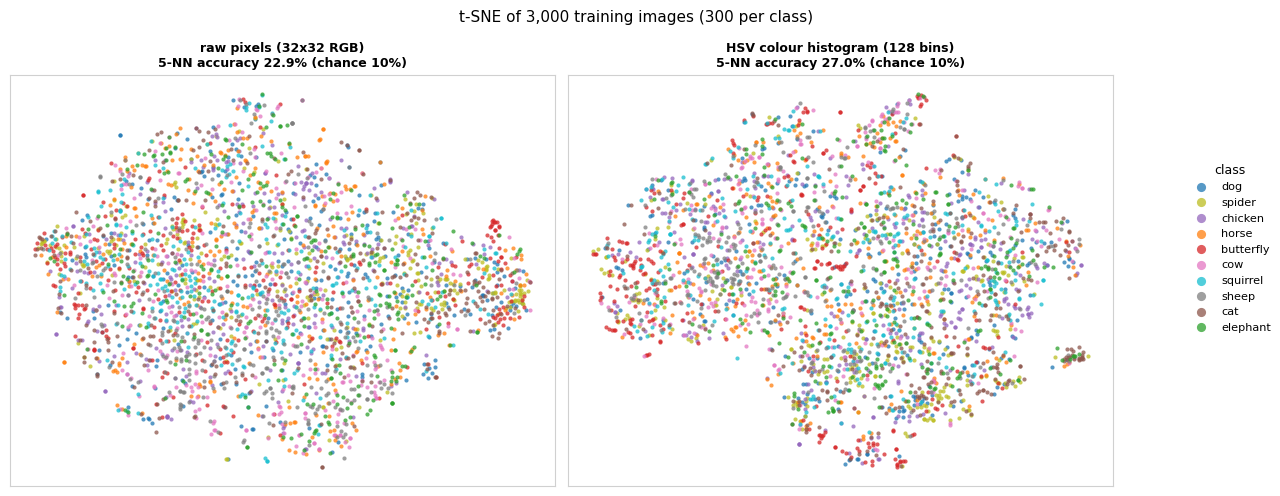

[saved]  animals10_eda/figures/eda_13_tsne.png
[saved]  animals10_eda/slides/eda_13_tsne.png
caption: t-SNE of a stratified training subset. raw pixels (32x32 RGB): 5-NN accuracy 22.9%; HSV colour histogram (128 bins): 5-NN accuracy 27.0% (chance 10%). Comparing these numbers with a trained model's accuracy shows how much learned features add over raw pixels and colour.


In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

_rng = np.random.default_rng(SEED)
TSNE_IDX = np.sort(np.concatenate([_rng.choice(np.intersect1d(np.flatnonzero(LABELS == c), TR),
                                               min(TSNE_PER_CLASS, int(((LABELS == c) & (SPLIT == "train")).sum())),
                                               replace=False) for c in range(NUM_CLASSES)]))
Y_TSNE = LABELS[TSNE_IDX]


def l2rows(X):
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12)


def feature_sets():
    sets = {}
    small = np.stack([np.asarray(Image.fromarray(t).resize((32, 32), Image.BILINEAR)) for t in THUMBS[TSNE_IDX]])
    sets["raw pixels (32x32 RGB)"] = small.reshape(len(small), -1).astype(np.float32) / 255
    hists = []
    for t in THUMBS[TSNE_IDX]:
        hsv = cv2.cvtColor(t, cv2.COLOR_RGB2HSV)
        h = cv2.calcHist([hsv], [0, 1, 2], None, [8, 4, 4], [0, 180, 0, 256, 0, 256]).flatten()
        hists.append(np.sqrt(h / max(h.sum(), 1)))
    sets["HSV colour histogram (128 bins)"] = l2rows(np.array(hists, dtype=np.float32))
    return sets


def embed_all():
    out = {}
    for name, X in feature_sets().items():
        X = (X - X.mean(0)) / (X.std(0) + 1e-6)
        Z = PCA(n_components=min(50, X.shape[1], len(X) - 1), random_state=SEED).fit_transform(X)
        knn = cross_val_score(KNeighborsClassifier(5), Z, Y_TSNE, cv=5).mean()
        E = TSNE(n_components=2, perplexity=min(30, len(Z) // 4), init="pca", random_state=SEED).fit_transform(Z)
        out[name] = (E, float(knn))
        print(f"{name}: 5-NN accuracy {knn:.3f}")
    return out


TSNE_CACHE = os.path.join(CACHE_DIR, f"tsne_{TSNE_PER_CLASS}.pkl")
TSNE_DEPS = STATS_DEPS
if needs_build(TSNE_CACHE, "tsne", TSNE_DEPS):
    EMB = embed_all()
    with open(TSNE_CACHE, "wb") as f:
        pickle.dump(EMB, f)
else:
    with open(TSNE_CACHE, "rb") as f:
        EMB = pickle.load(f)
KEY["knn5_accuracy"] = {k: v[1] for k, v in EMB.items()}


def fig_tsne():
    fig, axes = plt.subplots(1, len(EMB), figsize=(5.6 * len(EMB) + 1.6, 5.0), squeeze=False)
    for ax, (name, (E, knn)) in zip(axes[0], EMB.items()):
        for c in ORDER:
            m = Y_TSNE == CLASS_NAMES.index(c)
            ax.scatter(E[m, 0], E[m, 1], s=9, color=CLASS_COLORS[c], alpha=0.75, lw=0, label=c)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(True); s.set_color("#d0d0d0")
        ax.set_title(f"{name}\n5-NN accuracy {100 * knn:.1f}% (chance 10%)", fontsize=fs(1.0))
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="center right", markerscale=2.2, title="class", fontsize=fs(0.9))
    fig.suptitle(f"t-SNE of {len(TSNE_IDX):,} training images ({TSNE_PER_CLASS} per class)")
    fig.tight_layout(rect=(0, 0, 1 - 1.5 / fig.get_figwidth(), 1))
    return fig


save_figure("eda_13_tsne", fig_tsne,
            "t-SNE of a stratified training subset. " + "; ".join(
                f"{k}: 5-NN accuracy {100 * v[1]:.1f}%" for k, v in EMB.items()) +
            " (chance 10%). Comparing these numbers with a trained model's accuracy shows how much learned "
            "features add over raw pixels and colour.", deps=[TSNE_CACHE], width=1000)

# 15. Summary and download
`eda_summary.md`: every figure / table with its caption (numbers filled in); `eda_key_numbers.json`.

In [ ]:
def _json(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    return str(o)


with open(os.path.join(EDA_DIR, "eda_key_numbers.json"), "w") as f:
    json.dump(KEY, f, indent=1, default=_json)
lines = ["# Animals-10 EDA: figures and captions", "",
         f"Report figures: `{EDA_DIR}` (PNG + PDF). Slide figures: `{SLIDE_DIR}` (PNG, 300 dpi, no title).", ""]
seen = set()
for name, cap in SUMMARY:
    if name in seen:
        continue
    seen.add(name)
    lines += [f"**{name}** - {cap}", ""]
with open(os.path.join(EDA_DIR, "eda_summary.md"), "w") as f:
    f.write("\n".join(lines))
print("\n".join(lines))
print("\nFiles in", EDA_DIR)
print(sorted(f for f in os.listdir(EDA_DIR) if not f.startswith(".")))

import zipfile
ZIP = OUT_DIR.rstrip("/") + ".zip"            # figures, slides, tables, summary, splits (the cache is left out)
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, fnames in os.walk(OUT_DIR):
        if os.path.abspath(root).startswith(os.path.abspath(CACHE_DIR)):
            continue
        for f in fnames:
            z.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), os.path.dirname(os.path.abspath(OUT_DIR))))
print(f"\nOutputs zipped to {ZIP} ({os.path.getsize(ZIP) / 2 ** 20:.1f} MB)")
# if IN_COLAB:
#     from google.colab import files
#     files.download(ZIP)

# Animals-10 EDA: figures and captions

Report figures: `animals10_eda/figures` (PNG + PDF). Slide figures: `animals10_eda/slides` (PNG, 300 dpi, no title).

**eda_01_class_counts (table)** - 26179 images in 10 classes; dog is the largest (4863), elephant the smallest (1446), imbalance ratio 3.36:1.

**eda_01_class_counts** - Images per class. The dataset is imbalanced: dog has 4,863 images (18.6%), elephant 1,446 (5.5%), a 3.4x ratio, so macro-averaged metrics are worth reporting next to accuracy.

**eda_02_split_distribution** - Class share in each split. Stratification keeps every class share within 0.02 percentage points across train, validation and test.

**eda_03_sample_grid** - Random training images of every class (aspect ratio kept). Images are web photos with varied backgrounds, poses, scales and several animals per picture.

**eda_04_image_size_stats (table)** - Image size statistics. Median 300 x 225 px; 90% of the images have a longest side of exactly 300 px.

**eda_04_ima